<a href="https://colab.research.google.com/github/atulyapanda70/ph1050-group1/blob/main/part1_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Gravitational parameter in AU, years and solar masses
GM = 4 * np.pi**2

# Initial conditions for a circular orbit of radius 1 AU
x0 = 1.0
y0 = 0.0
vx0 = 0.0
vy0 = 2 * np.pi

# Simulation settings
dt = 0.001
t_final = 1.0

In [ ]:

def derivatives(state):
    """
    state = [x, y, vx, vy]

    Returns the derivatives:
    dx/dt, dy/dt, dvx/dt, dvy/dt
    """

    x, y, vx, vy = state

    r = np.sqrt(x**2 + y**2)

    # Newton's gravitational acceleration
    ax = -GM * x / r**3
    ay = -GM * y / r**3

    return np.array([vx, vy, ax, ay])


In [ ]:

def euler_step(state, dt):

    # Calculate slope at current position
    k1 = derivatives(state)

    # Update position and velocity
    return state + dt * k1


In [ ]:

def rk4_step(state, dt):

    # Four slope estimates
    k1 = derivatives(state)
    k2 = derivatives(state + dt*k1/2)
    k3 = derivatives(state + dt*k2/2)
    k4 = derivatives(state + dt*k3)

    # Weighted average of the four slopes
    return state + (dt/6)*(k1 + 2*k2 + 2*k3 + k4)


In [ ]:

def simulate(method, dt, t_final=1.0):

    # Initial state
    state = np.array([x0, y0, vx0, vy0])

    # Number of time steps
    n = int(round(t_final/dt))

    # Store time and states
    times = np.linspace(0, t_final, n+1)
    states = np.zeros((n+1, 4))

    states[0] = state

    # Perform numerical integration
    for i in range(n):
        state = method(state, dt)
        states[i+1] = state

    return times, states


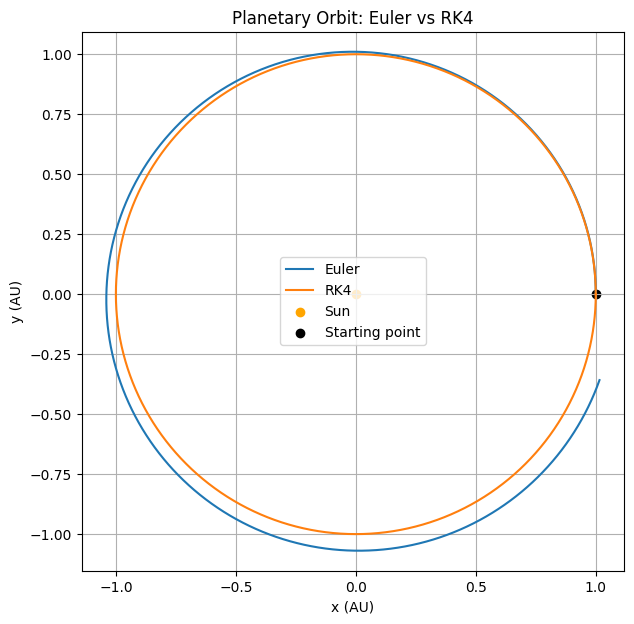

In [ ]:

t_euler, sol_euler = simulate(euler_step, dt, t_final)

t_rk4, sol_rk4 = simulate(rk4_step, dt, t_final)

# Extract positions
x_euler = sol_euler[:, 0]
y_euler = sol_euler[:, 1]

x_rk4 = sol_rk4[:, 0]
y_rk4 = sol_rk4[:, 1]

# Plot the orbits
plt.figure(figsize=(7, 7))

plt.plot(x_euler, y_euler, label="Euler")
plt.plot(x_rk4, y_rk4, label="RK4")

plt.scatter(0, 0, color="orange", label="Sun")
plt.scatter(1, 0, color="black", label="Starting point")

plt.xlabel("x (AU)")
plt.ylabel("y (AU)")
plt.title("Planetary Orbit: Euler vs RK4")
plt.axis("equal")
plt.legend()
plt.grid()
plt.show()
